# 05 · Power analysis

**Questions:**

1. What is the smallest effect this experiment could reliably detect for each metric (the **minimum detectable effect**, MDE)?
2. How many customers would an experiment need to detect a given effect?
3. How much does covariate adjustment (notebook 04) change that?

**Method:** the standard normal-approximation formulas for a two-sided test at level $\alpha$ with power $1-\beta$:

$$\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta})\;\sigma\,\sqrt{\tfrac{1}{n_t} + \tfrac{1}{n_c}}, \qquad n_{\text{per arm}} = 2\,\frac{(z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2}{\text{MDE}^2}.$$

Defaults: $\alpha = 0.05$, power 80%. $\sigma$ is the control arm's standard deviation ($\sqrt{p(1-p)}$ for rates), the usual choice when planning, because the treated arm's variance is unknown in advance. The functions are checked against `statsmodels` in the tests.

Not used: simulation-based power. With ~21,000 customers per arm, notebook 03 showed the normal approximation holds even for spend (bootstrap and Welch intervals agree to half a cent), so simulation would add complexity without changing the answer.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from hillstrom.data import load_customers
from hillstrom.effects import diff_means_welch
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_PRIMARY, TEXT_SECONDARY, apply_style, save_figure
from hillstrom.power import mde_means, required_n_means

apply_style()
df = load_customers()
n_arm = df["arm"].value_counts()
control = df[df["arm"] == "control"]
METRICS = ["visit", "conversion", "spend"]
SCALE = {"visit": (100, "pp"), "conversion": (100, "pp"), "spend": (1, "$")}

## 1. What could this experiment detect?

MDE for an email vs No E-Mail comparison at the actual arm sizes (~21,300 each), next to the observed effects from notebook 03. The second MDE column uses $\alpha = 0.05/9$: under the Holm correction across 9 tests, the smallest p-value is compared with 0.05/9, so this is the MDE in the worst case for that correction.

In [2]:
mde_rows = []
for metric in METRICS:
    sd = control[metric].std()
    scale, unit = SCALE[metric]
    row = {
        "metric": metric,
        "unit": unit,
        "control_sd": sd,
        "MDE (alpha 0.05)": scale * mde_means(sd, n_arm["mens"], n_arm["control"]),
        "MDE (alpha 0.05/9)": scale * mde_means(sd, n_arm["mens"], n_arm["control"], alpha=0.05 / 9),
    }
    for email in ["mens", "womens"]:
        effect = df.loc[df["arm"] == email, metric].mean() - control[metric].mean()
        row[f"observed: {ARM_LABELS[email]}"] = scale * effect
    mde_rows.append(row)
mde_table = pd.DataFrame(mde_rows)
mde_table.style.format({c: "{:.3f}" for c in mde_table.columns if c not in ("metric", "unit")}).hide(axis="index")

metric,unit,control_sd,MDE (alpha 0.05),MDE (alpha 0.05/9),observed: Mens E-Mail,observed: Womens E-Mail
visit,pp,0.308,0.836,1.079,7.659,4.523
conversion,pp,0.075,0.205,0.264,0.681,0.311
spend,$,11.588,0.315,0.406,0.770,0.424


Every email-vs-control effect is above the MDE, but not all by a wide margin:

- The **Mens** effects are 2.4 to 9 times the MDE: comfortably powered.
- Two **Womens** effects are close calls. Conversion (+0.31 pp) and spend (+\$0.42) are only modestly above the MDE at $\alpha = 0.05$, and at the stricter $\alpha = 0.05/9$ the spend effect only just clears it (\$0.42 vs \$0.41). An experiment of this size had a real chance of missing the Womens email's effect on spend.

The MDE uses the control arm's spread. The email arms' spend is more spread out (standard deviation about \$15-18 vs \$11.6), so the real MDE for spend is somewhat larger than shown, which matters for the next comparison.

## 2. The underpowered comparison: Mens vs Womens on spend

Comparing the two emails with each other is harder than comparing either with no email: the difference is smaller, and both arms have the larger, email-driven spend variance. The power of that test *at the effect size actually observed* is:

In [3]:
y_m = df.loc[df["arm"] == "mens", "spend"].to_numpy()
y_w = df.loc[df["arm"] == "womens", "spend"].to_numpy()
mw = diff_means_welch(y_m, y_w)
se = np.sqrt(y_m.var(ddof=1) / len(y_m) + y_w.var(ddof=1) / len(y_w))
power_at_observed = stats.norm.cdf(abs(mw.estimate) / se - stats.norm.ppf(0.975))
mde_mw = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * se
print(f"Observed difference: ${mw.estimate:.3f}  (SE ${se:.3f})")
print(f"MDE for this comparison at 80% power: ${mde_mw:.3f}")
print(f"Power to detect a true difference of ${mw.estimate:.3f}: {power_at_observed:.0%}")

Observed difference: $0.345  (SE $0.160)
MDE for this comparison at 80% power: $0.447
Power to detect a true difference of $0.345: 58%


The Mens vs Womens spend test had only about a coin-flip-plus chance of detecting a true difference of the size it found. It did come out significant (Holm-adjusted p ≈ 0.03, notebook 03), but this has a known catch, the **winner's curse**: when a test has low power, the estimates that happen to cross the significance line are on average larger than the true effect, because only the lucky high draws make it. So the \$0.35 gap is likely an overestimate, and the true difference could be considerably smaller. The direction (Mens ahead) is supported by every other metric; the size is not pinned down.

Visit and conversion comparisons between the two emails do not have this problem: their observed differences are several times their MDEs.

## 3. How many customers for a given effect?

Customers needed **per arm** for 80% power at $\alpha = 0.05$, for a range of effect sizes, without and with regression adjustment. Adjustment multiplies the required sample by $(1 - r)$, where $r$ is the variance reduction measured in notebook 04 (recomputed here for Mens vs No E-Mail).

In [4]:
from hillstrom.variance import regression_adjusted_effect

COVARIATES = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
reduction = {}
for metric in METRICS:
    raw = regression_adjusted_effect(df, metric, "mens", covariates=[])
    adj = regression_adjusted_effect(df, metric, "mens", covariates=COVARIATES)
    reduction[metric] = 1 - ((adj.ci_high - adj.ci_low) / (raw.ci_high - raw.ci_low)) ** 2

EFFECTS = {"visit": [0.005, 0.01, 0.02, 0.05], "conversion": [0.001, 0.0025, 0.005], "spend": [0.10, 0.25, 0.50, 0.77]}
n_rows = []
for metric, effects in EFFECTS.items():
    sd = control[metric].std()
    scale, unit = SCALE[metric]
    for effect in effects:
        n = required_n_means(sd, effect)
        n_rows.append(
            {
                "metric": metric,
                "effect": f"{scale * effect:g} {unit}",
                "n per arm": n,
                "variance reduction": reduction[metric],
                "n per arm, adjusted": required_n_means(sd * np.sqrt(1 - reduction[metric]), effect),
            }
        )
pd.DataFrame(n_rows).style.format(
    {"n per arm": "{:,}", "n per arm, adjusted": "{:,}", "variance reduction": "{:.1%}"}
).hide(axis="index")

metric,effect,n per arm,variance reduction,"n per arm, adjusted"
visit,0.5 pp,"59,589",2.9%,"57,872"
visit,1 pp,"14,898",2.9%,"14,468"
visit,2 pp,"3,725",2.9%,"3,617"
visit,5 pp,596,2.9%,579
conversion,0.1 pp,"89,377",0.3%,"89,123"
conversion,0.25 pp,"14,301",0.3%,"14,260"
conversion,0.5 pp,"3,576",0.3%,"3,565"
spend,0.1 $,"210,800",0.3%,"210,270"
spend,0.25 $,"33,728",0.3%,"33,644"
spend,0.5 $,"8,432",0.3%,"8,411"


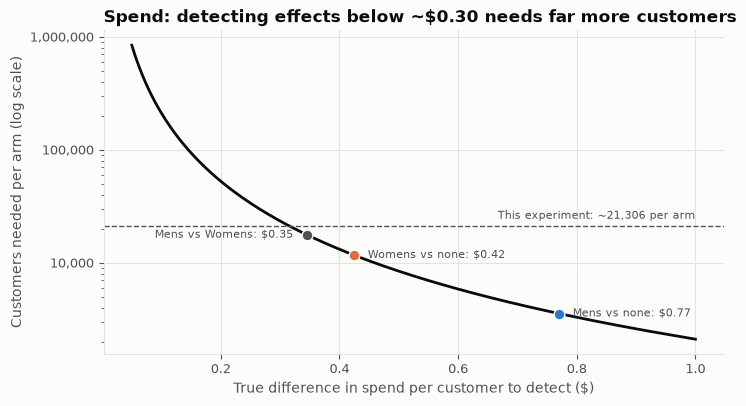

In [5]:
sd_spend = control["spend"].std()
effects = np.linspace(0.05, 1.0, 200)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(effects, [required_n_means(sd_spend, e) for e in effects], color=TEXT_PRIMARY, lw=2)
ax.axhline(n_arm["control"], color=TEXT_SECONDARY, lw=1, ls="--")
ax.text(1.0, n_arm["control"] * 1.15, f"This experiment: ~{n_arm['control']:,} per arm", ha="right", fontsize=8,
        color=TEXT_SECONDARY)
spend_mean = df.groupby("arm")["spend"].mean()
observed = [
    ("Mens vs none", spend_mean["mens"] - spend_mean["control"], ARM_COLORS["mens"], "right"),
    ("Womens vs none", spend_mean["womens"] - spend_mean["control"], ARM_COLORS["womens"], "right"),
    ("Mens vs Womens", spend_mean["mens"] - spend_mean["womens"], TEXT_SECONDARY, "left"),
]
for label, e, color, side in observed:
    n_needed = required_n_means(sd_spend, e)
    ax.scatter(e, n_needed, s=60, color=color, edgecolor="white", linewidth=1, zorder=3)
    ax.annotate(f"{label}: ${e:.2f}", (e, n_needed), xytext=(10 if side == "right" else -10, 0),
                textcoords="offset points", fontsize=8, ha="left" if side == "right" else "right",
                va="center", color=TEXT_SECONDARY)
ax.set_yscale("log")
# Plain tick labels: the shared style turns off math text, which log-axis labels rely on.
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("True difference in spend per customer to detect ($)")
ax.set_ylabel("Customers needed per arm (log scale)")
ax.set_title("Spend: detecting effects below ~$0.30 needs far more customers", loc="left")
save_figure(fig, "05_required_sample_size_spend")
plt.show()

The curve uses the control arm's spend SD. Points mark the observed effects from notebook 03; any point below the dashed line was detectable with 80% power at this experiment's size. The Mens vs Womens point sits close to the line, and with the email arms' larger variance the true requirement is higher still, which is the underpowered comparison from section 2.

## Takeaways

- **The experiment was well powered for the Mens email**, whose effects are 2.4 to 9 times the minimum detectable effect. **The Womens email's spend and conversion effects were close to the limit** of what this experiment could detect, especially under the multiple-comparison correction.
- **It was not well powered for comparing the two emails on spend.** The power for the observed \$0.35 gap is around 58%; the significant result there probably overstates the gap (winner's curse).
- **Spend is the expensive metric.** Detecting a \$0.10 change in spend per customer would need about 210,000 customers per arm, roughly ten times this experiment. Visits need far fewer customers for effects of business interest. This is the power-analysis view of why notebooks 06-07 had to rely on visits.
- **Covariate adjustment barely changes these numbers in this dataset** (about 3% fewer customers for visits, under 1% for spend), consistent with notebook 04. With a pre-period version of the same metric, the savings could be much larger.

**What we cannot claim:** these calculations assume the planning standard deviation is right; for spend, the email arms' larger variance means the real requirements are somewhat higher than shown.